In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *


In [2]:
nx=ny=10
ds_nepal=xr.open_dataset('/home/santolam/NST.2000.01.01.00.GRc.nc')#['SH']#[nx:-nx,ny:-ny]
dsSH_nepal=ds_nepal['SH'][nx:-nx,ny:-ny]
dsICE_nepal=ds_nepal['ICE'][nx:-nx,ny:-ny]
LONS_nepal,LATS_nepal=ds_nepal.LON[nx:-nx,ny:-ny],ds_nepal.LAT[nx:-nx,ny:-ny]

ds_pamir=xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')#['SH']#[nx:-nx,ny:-ny]
dsSH_pamir=ds_pamir['SH'][nx:-nx,ny:-ny]
dsICE_pamir=ds_pamir['ICE'][nx:-nx,ny:-ny]
LONS_pamir,LATS_pamir=ds_pamir.LON[nx:-nx,ny:-ny],ds_pamir.LAT[nx:-nx,ny:-ny]

In [14]:
sourceTopo='/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'

In [16]:
dsSH_cru=xr.open_dataset(sourceTopo+'gmted_on_cru_hma_grid.nc')['elevation']
dsSH_cru

<xarray.DataArray 'elevation' (lat: 50, lon: 100)>
array([[   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    8],
       [   0,    0,    0, ...,    0,    0,    7],
       ...,
       [  49,   54,   58, ...,  826,  802, 1000],
       [  33,   48,   55, ...,  935,  811,  764],
       [  29,   33,   44, ..., 1137, 1087,  982]], dtype=int16)
Coordinates:
  * lon      (lon) float32 60.25 60.75 61.25 61.75 ... 108.2 108.8 109.2 109.8
  * lat      (lat) float32 20.25 20.75 21.25 21.75 ... 43.25 43.75 44.25 44.75
Attributes:
    standard_name:        altitude
    long_name:            altitude above the geoid
    units:                m
    geoid:                WGS84
    gridcell_centres:     longitude latitude
    gridcell_bounds:      longitude_bounds latitude_bounds
    ancillary_variables:  elevation_stddev
    minimum_value:        -412
    maximum_value:        7237

In [17]:
dsSH_aphro=xr.open_dataset(sourceTopo+'gmted_on_aphro.nc')['elevation']
dsSH_aphro

<xarray.DataArray 'elevation' (latitude: 280, longitude: 360)>
[100800 values with dtype=int16]
Coordinates:
  * longitude  (longitude) float64 60.12 60.38 60.62 60.88 ... 149.4 149.6 149.9
  * latitude   (latitude) float64 -14.88 -14.62 -14.38 ... 54.38 54.62 54.88
Attributes:
    standard_name:        altitude
    long_name:            altitude above the geoid
    units:                m
    geoid:                WGS84
    gridcell_centres:     longitude latitude
    gridcell_bounds:      longitude_bounds latitude_bounds
    ancillary_variables:  elevation_stddev
    minimum_value:        -412
    maximum_value:        7237

In [7]:
plotsDir="/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/"

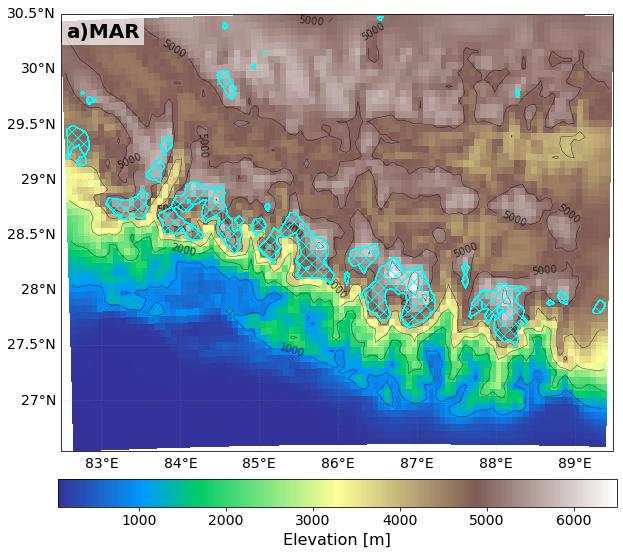

In [23]:
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

CS = ax.pcolormesh(
    LONS_nepal, LATS_nepal, dsSH_nepal,
    transform=ccrs.PlateCarree(),
    cmap='terrain',
    shading="auto"
)

# Gridlines
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color="gray",alpha=0.3,linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False

# Elevation contours
SH = ax.contour(
    LONS_nepal, LATS_nepal, dsSH_nepal,
     levels=[1000,2000,3000,4000,5000,6000,7000],
    colors="k",linewidths=0.5, alpha=0.7,transform=ccrs.PlateCarree())

ax.clabel(SH, inline=True, fontsize=10, fmt="%d")

# Glacier mask
ICE = ax.contourf(
    LONS_nepal, LATS_nepal, dsICE_nepal,
    levels=[20, 100],hatches=['XX', 'XX'],colors='none',transform=ccrs.PlateCarree(),zorder=4)

for coll in ICE.collections:
    coll.set_edgecolor('cyan')
    coll.set_linewidth(0.6)
    coll.set_facecolor('none')
    coll.set_zorder(6)

# Panel label
ax.text(
    0.01, 0.98, 'a)MAR',
    transform=ax.transAxes,fontsize=20,fontweight='bold', va='top', ha='left', 
    bbox=dict(facecolor='white', alpha=0.7,edgecolor='none'))

ax.set_aspect(1.4)
# Colorbar
cbar = plt.colorbar(
    CS,ax=ax,orientation='horizontal',pad=0.05,shrink=0.8)

cbar.set_label('Elevation [m]', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plotname = f'topo_MAR_nepal_GRc'
plt.savefig(f"{plotsDir}{plotname}.png",            bbox_inches="tight", dpi=300)

plt.show()

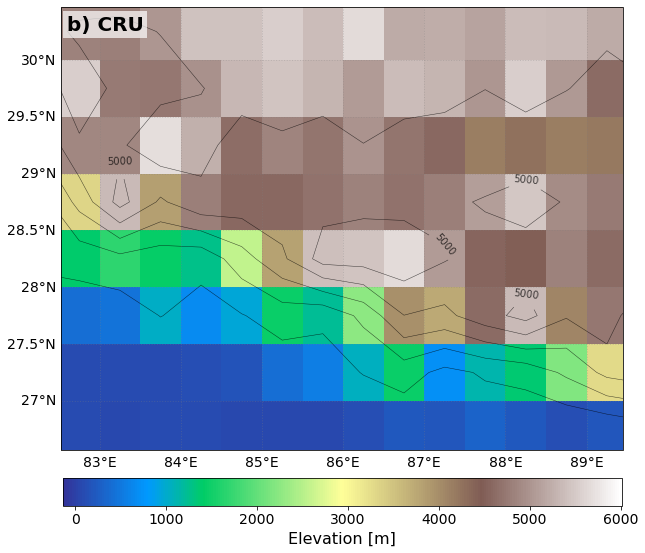

In [24]:
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

CS = ax.pcolormesh(
    dsSH_cru.lon,dsSH_cru.lat,dsSH_cru,
    transform=ccrs.PlateCarree(),
    cmap='terrain',
    shading="auto"
)
ax.set_extent([
    float(LONS_nepal.min()),
    float(LONS_nepal.max()),
    float(LATS_nepal.min()),
    float(LATS_nepal.max())
], crs=ccrs.PlateCarree())

# Gridlines
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color="gray",alpha=0.3,linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False

# Elevation contours
SH = ax.contour(
    dsSH_cru.lon,dsSH_cru.lat,dsSH_cru,
     levels=[1000,2000,3000,4000,5000,6000,7000],
    colors="k",linewidths=0.5, alpha=0.7,transform=ccrs.PlateCarree())

ax.clabel(SH, inline=True, fontsize=10, fmt="%d")


# Panel label
ax.text(
    0.01, 0.98, 'b) CRU',
    transform=ax.transAxes,fontsize=20,fontweight='bold', va='top', ha='left', 
    bbox=dict(facecolor='white', alpha=0.7,edgecolor='none'))

ax.set_aspect(1.4)
# Colorbar
cbar = plt.colorbar(
    CS,ax=ax,orientation='horizontal',pad=0.05,shrink=0.8)

cbar.set_label('Elevation [m]', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plotname = f'topo_cru_nepal'
plt.savefig(f"{plotsDir}{plotname}.png",            bbox_inches="tight", dpi=300)

plt.show()

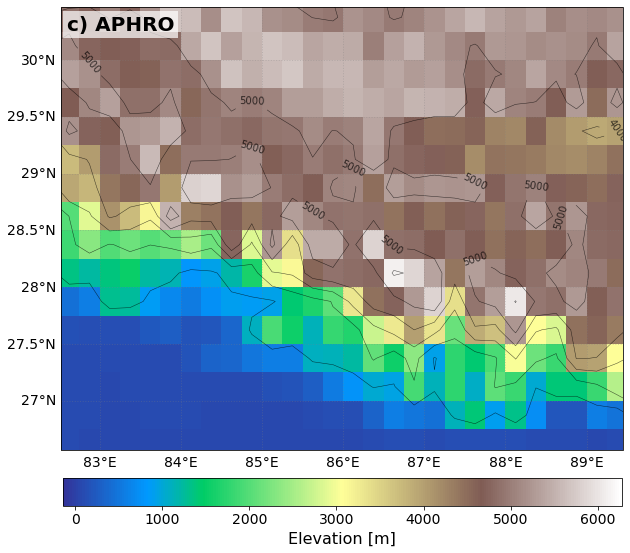

In [27]:
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

CS = ax.pcolormesh(
    dsSH_aphro.longitude,dsSH_aphro.latitude,dsSH_aphro,
    transform=ccrs.PlateCarree(),
    cmap='terrain',
    shading="auto"
)
ax.set_extent([
    float(LONS_nepal.min()),
    float(LONS_nepal.max()),
    float(LATS_nepal.min()),
    float(LATS_nepal.max())
], crs=ccrs.PlateCarree())

# Gridlines
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color="gray",alpha=0.3,linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False

# Elevation contours
SH = ax.contour(
    dsSH_aphro.longitude,dsSH_aphro.latitude,dsSH_aphro,
     levels=[1000,2000,3000,4000,5000,6000,7000],
    colors="k",linewidths=0.5, alpha=0.7,transform=ccrs.PlateCarree())

ax.clabel(SH, inline=True, fontsize=10, fmt="%d")


# Panel label
ax.text(
    0.01, 0.98, 'c) APHRO',
    transform=ax.transAxes,fontsize=20,fontweight='bold', va='top', ha='left', 
    bbox=dict(facecolor='white', alpha=0.7,edgecolor='none'))

ax.set_aspect(1.4)
# Colorbar
cbar = plt.colorbar(
    CS,ax=ax,orientation='horizontal',pad=0.05,shrink=0.8)

cbar.set_label('Elevation [m]', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plotname = f'topo_aphro_nepal'
plt.savefig(f"{plotsDir}{plotname}.png",            bbox_inches="tight", dpi=300)

plt.show()

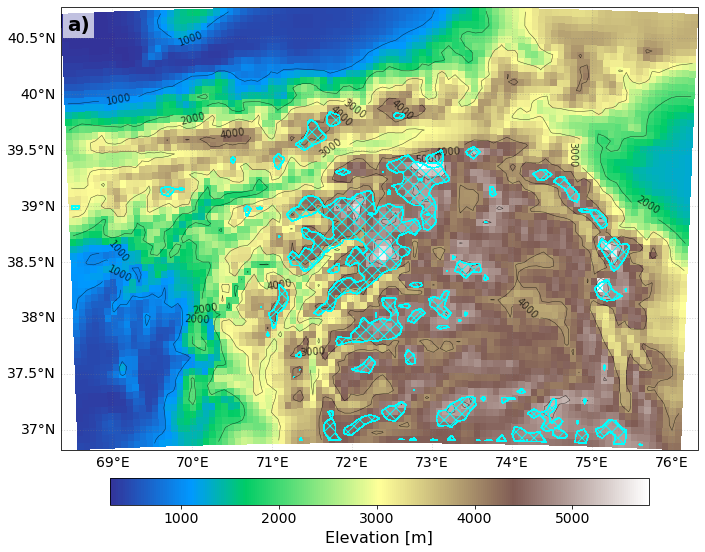

In [12]:
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

CS = ax.pcolormesh(
    LONS_pamir, LATS_pamir, dsSH_pamir,
    transform=ccrs.PlateCarree(),
    cmap='terrain',
    shading="auto"
)

# Gridlines
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color="gray",alpha=0.3,linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False

# Elevation contours
SH = ax.contour(
    LONS_pamir, LATS_pamir, dsSH_pamir,
     levels=[1000,2000,3000,4000,5000,6000,7000],
    colors="k",linewidths=0.5, alpha=0.7,transform=ccrs.PlateCarree())

ax.clabel(SH, inline=True, fontsize=10, fmt="%d")

# Glacier mask
ICE = ax.contourf(
    LONS_pamir, LATS_pamir, dsICE_pamir,
    levels=[20, 100],hatches=['XX', 'XX'],colors='none',transform=ccrs.PlateCarree(),zorder=4)

for coll in ICE.collections:
    coll.set_edgecolor('cyan')
    coll.set_linewidth(0.6)
    coll.set_facecolor('none')
    coll.set_zorder(6)

# Panel label
ax.text(
    0.01, 0.98, 'a)',
    transform=ax.transAxes,fontsize=20,fontweight='bold', va='top', ha='left', 
    bbox=dict(facecolor='white', alpha=0.7,edgecolor='none'))

ax.set_aspect(1.4)
# Colorbar
cbar = plt.colorbar(
    CS,ax=ax,orientation='horizontal',pad=0.05,shrink=0.8)

cbar.set_label('Elevation [m]', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plotname = f'topo_MAR_pamir_GRi'
plt.savefig(f"{plotsDir}{plotname}.png",            bbox_inches="tight", dpi=300)

plt.show()

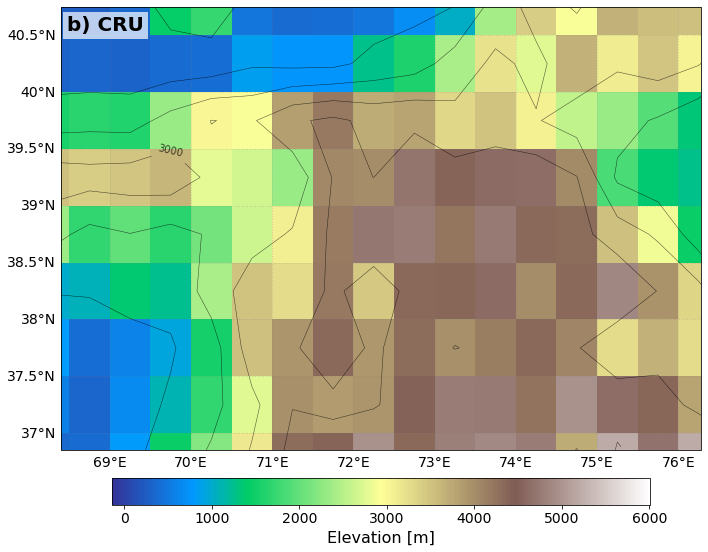

In [26]:
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

CS = ax.pcolormesh(
    dsSH_cru.lon,dsSH_cru.lat,dsSH_cru,
    transform=ccrs.PlateCarree(),
    cmap='terrain',
    shading="auto"
)
ax.set_extent([
    float(LONS_pamir.min()),
    float(LONS_pamir.max()),
    float(LATS_pamir.min()),
    float(LATS_pamir.max())
], crs=ccrs.PlateCarree())

# Gridlines
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color="gray",alpha=0.3,linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False

# Elevation contours
SH = ax.contour(
    dsSH_cru.lon,dsSH_cru.lat,dsSH_cru,
     levels=[1000,2000,3000,4000,5000,6000,7000],
    colors="k",linewidths=0.5, alpha=0.7,transform=ccrs.PlateCarree())

ax.clabel(SH, SH.levels,inline=True, fontsize=10, fmt="%d")


# Panel label
ax.text(
    0.01, 0.98, 'b) CRU',
    transform=ax.transAxes,fontsize=20,fontweight='bold', va='top', ha='left', 
    bbox=dict(facecolor='white', alpha=0.7,edgecolor='none'))

ax.set_aspect(1.4)
# Colorbar
cbar = plt.colorbar(
    CS,ax=ax,orientation='horizontal',pad=0.05,shrink=0.8)

cbar.set_label('Elevation [m]', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plotname = f'topo_cru_pamir'
plt.savefig(f"{plotsDir}{plotname}.png",            bbox_inches="tight", dpi=300)

plt.show()

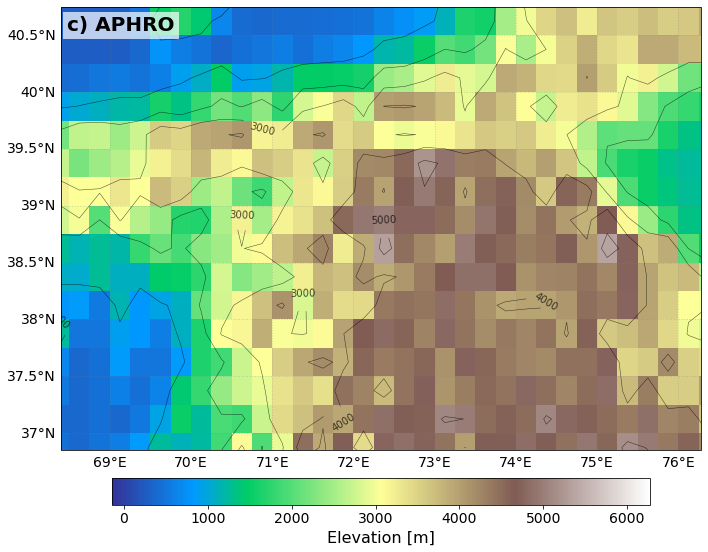

In [28]:
fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

CS = ax.pcolormesh(
    dsSH_aphro.longitude,dsSH_aphro.latitude,dsSH_aphro,
    transform=ccrs.PlateCarree(),
    cmap='terrain',
    shading="auto"
)
ax.set_extent([
    float(LONS_pamir.min()),
    float(LONS_pamir.max()),
    float(LATS_pamir.min()),
    float(LATS_pamir.max())
], crs=ccrs.PlateCarree())

# Gridlines
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color="gray",alpha=0.3,linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False

# Elevation contours
SH = ax.contour(
    dsSH_aphro.longitude,dsSH_aphro.latitude,dsSH_aphro,
     levels=[1000,2000,3000,4000,5000,6000,7000],
    colors="k",linewidths=0.5, alpha=0.7,transform=ccrs.PlateCarree())

ax.clabel(SH, inline=True, fontsize=10, fmt="%d")


# Panel label
ax.text(
    0.01, 0.98, 'c) APHRO',
    transform=ax.transAxes,fontsize=20,fontweight='bold', va='top', ha='left', 
    bbox=dict(facecolor='white', alpha=0.7,edgecolor='none'))

ax.set_aspect(1.4)
# Colorbar
cbar = plt.colorbar(
    CS,ax=ax,orientation='horizontal',pad=0.05,shrink=0.8)

cbar.set_label('Elevation [m]', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plotname = f'topo_aphro_pamir'
plt.savefig(f"{plotsDir}{plotname}.png",            bbox_inches="tight", dpi=300)

plt.show()